# 01 — Ingestão, validação e pré-processamento do dataset Beans

**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Este notebook cobre a primeira etapa do projeto: carregar o dataset do Hugging Face, inspecionar os splits, validar as classes e construir um pipeline inicial de redimensionamento e normalização das imagens.


## 1. Problema e objetivo

O problema é uma **classificação multiclasse de imagens**. A entrada é uma fotografia de folha de feijão e a saída esperada é uma entre três classes: `angular_leaf_spot`, `bean_rust` ou `healthy`.

Nesta primeira etapa, o objetivo técnico é garantir uma ingestão reprodutível dos dados e preparar um pipeline de imagens consistente para os experimentos de EDA e modelagem que virão na sequência.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bean_leaf_disease.data.beans import (
    class_distribution,
    class_names,
    load_beans_dataset,
    make_tf_dataset,
    split_summary,
)
from bean_leaf_disease.utils.reproducibility import set_global_seed

SEED = 42
set_global_seed(SEED)
pd.set_option('display.max_columns', None)


I0000 00:00:1792543347.532562    9642 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792543347.633294    9642 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792543351.404549    9642 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/leo/Desktop/dev/github/bean-leaf-disease-challenge/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Ingestão do dataset via Hugging Face

In [3]:
dataset = load_beans_dataset()
dataset

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})

In [4]:
summary = split_summary(dataset)
summary

,split,label_id,class_name,count,proportion
0,train,0,angular_leaf_spot,345,0.333656
1,train,1,bean_rust,348,0.336557
2,train,2,healthy,341,0.329787
3,validation,0,angular_leaf_spot,44,0.330827
4,validation,1,bean_rust,45,0.338346
5,validation,2,healthy,44,0.330827
6,test,0,angular_leaf_spot,43,0.335938
7,test,1,bean_rust,43,0.335938
8,test,2,healthy,42,0.328125


## 3. Classes e distribuição por split

Antes de modelar, verificamos se os rótulos disponíveis correspondem às três classes esperadas e se existe algum indício de desbalanceamento entre treino, validação e teste.

In [5]:
labels = class_names(dataset)
labels

['angular_leaf_spot', 'bean_rust', 'healthy']

In [6]:
distribution = class_distribution(dataset)
distribution

,split,label_id,class_name,count,proportion
0,train,0,angular_leaf_spot,345,0.333656
1,train,1,bean_rust,348,0.336557
2,train,2,healthy,341,0.329787
3,validation,0,angular_leaf_spot,44,0.330827
4,validation,1,bean_rust,45,0.338346
5,validation,2,healthy,44,0.330827
6,test,0,angular_leaf_spot,43,0.335938
7,test,1,bean_rust,43,0.335938
8,test,2,healthy,42,0.328125


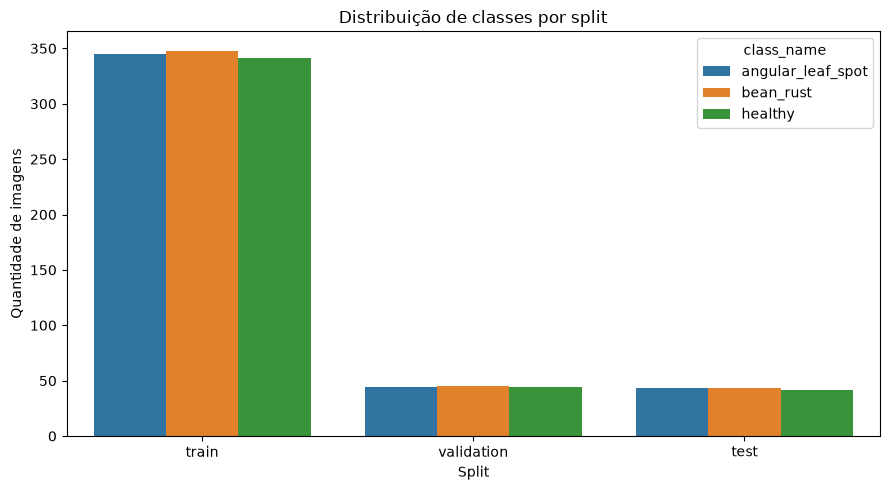

In [7]:
plt.figure(figsize=(9, 5))
sns.barplot(data=distribution, x='split', y='count', hue='class_name')
plt.title('Distribuição de classes por split')
plt.xlabel('Split')
plt.ylabel('Quantidade de imagens')
plt.tight_layout()
plt.show()

## 4. Inspeção visual de amostras

A inspeção visual ajuda a verificar resolução, enquadramento, iluminação e variabilidade antes de definir augmentation e arquitetura de rede.

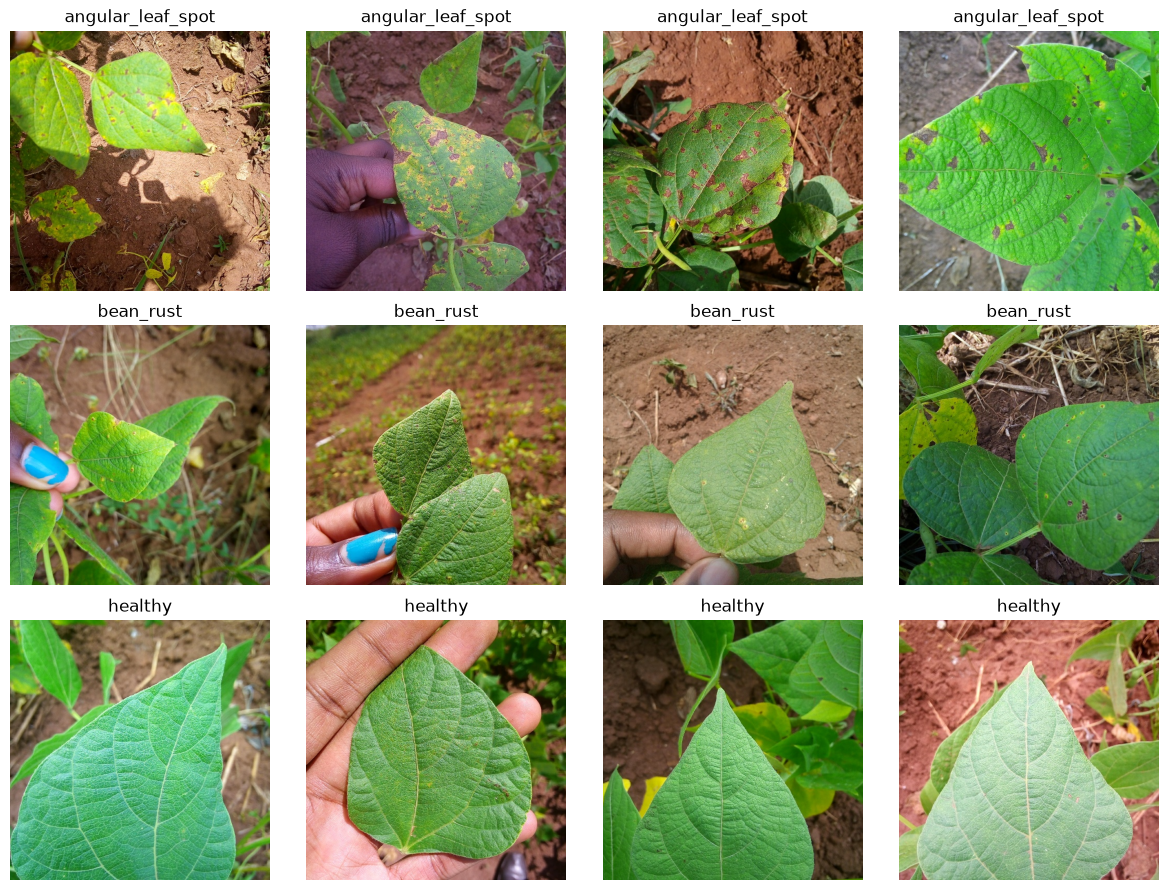

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, class_id in enumerate(range(len(labels))):
    class_samples = [s for s in dataset['train'] if s['labels'] == class_id][:4]
    for col, sample in enumerate(class_samples):
        axes[row, col].imshow(sample['image'])
        axes[row, col].set_title(labels[class_id])
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 5. Pipeline inicial: resize + normalização

Para padronizar a entrada dos modelos, adotamos inicialmente `224 × 224` pixels e normalização dos pixels para o intervalo `[0, 1]`. O valor 224 é compatível com várias arquiteturas populares de Transfer Learning e permite reaproveitar este pipeline depois.

In [9]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = make_tf_dataset(
    dataset['train'], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=SEED
)
val_ds = make_tf_dataset(
    dataset['validation'], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)
test_ds = make_tf_dataset(
    dataset['test'], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE
)

E0000 00:00:1792543395.604002    9642 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792543395.605698   11786 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792543395.634861    9642 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [10]:
images, y = next(iter(train_ds))
print('batch images:', images.shape)
print('batch labels:', y.shape)
print('min pixel:', float(images.numpy().min()))
print('max pixel:', float(images.numpy().max()))

I0000 00:00:1792543417.484895   12257 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


batch images: (32, 224, 224, 3)
batch labels: (32,)
min pixel: 0.0
max pixel: 1.0


## 6. Checks de qualidade iniciais

Estes checks servem para detectar problemas antes de qualquer treinamento: splits vazios, classes inesperadas e falhas no pipeline de imagem.

In [11]:
assert set(dataset.keys()) >= {'train', 'validation', 'test'}
assert len(labels) == 3
assert images.shape[1:] == (224, 224, 3)
assert 0.0 <= float(images.numpy().min())
assert float(images.numpy().max()) <= 1.0
print('Checks iniciais concluídos com sucesso.')

Checks iniciais concluídos com sucesso.


## 7. Artefatos para os próximas etapas

O notebook deixa prontos: (1) carregamento do dataset, (2) nomes das classes, (3) distribuição por split e (4) datasets TensorFlow pré-processados. Isso permite que a EDA continue sobre a base original e que o baseline consuma diretamente `train_ds`, `val_ds` e `test_ds`.


In [12]:
output_dir = Path('../data/processed')
output_dir.mkdir(parents=True, exist_ok=True)
distribution.to_csv(output_dir / 'class_distribution.csv', index=False)
summary.to_csv(output_dir / 'split_summary.csv', index=False)
print('Metadados salvos em data/processed/.')

Metadados salvos em data/processed/.
